<a href="https://colab.research.google.com/github/Ash-Daniels-Mo/HEART-DISEASE-ANALYSIS-BY-ASH-DANIELS/blob/main/HeartDiseasePred_in_R_(LogisticReg).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<p style="font-size:26px; font-weight:bold; line-height:2;">
<b>Objective of Project</b>
</p>

<p style="font-size:18px; line-height:1.8;">
Analyze the <b>Heart Disease</b> dataset to predict the presence of heart disease using
<b>logistic regression</b>. The dataset contains medical information about individuals,
and the goal is to explore how various factors contribute to the likelihood of heart disease.
</p>

<p style="font-size:22px; font-weight:bold; line-height:2; margin-top:20px;">
Dataset Source
</p>

<p style="font-size:18px; line-height:1.8;">
The dataset used for this analysis is available on Kaggle:<br>
<a href="https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset">
https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset
</a>
</p>

<p style="font-size:22px; font-weight:bold; line-height:2; margin-top:20px;">
Analytical Goal
</p>

<p style="font-size:18px; line-height:1.8;">
The aim of this project is to:
<ul style="font-size:18px; line-height:1.8;">
  <li>Perform exploratory analysis on the medical variables</li>
  <li>Build a <b>logistic regression model</b> to predict heart disease presence</li>
  <li>Interpret variable influence on heart disease risk</li>
  <li>Evaluate model performance using ROC and AUC</li>
</ul>
</p>


# 1. Data Preparation

# a. Download and Load the Dataset

In [ ]:
# Install necessary packages before beginning data analysis
install.packages(c("tidyverse",  # Data manipulation and visualization
                   "caret",      # Machine learning functions
                   "pROC"))      # ROC curve analysis

# Load packages
library(tidyverse)
library(caret)
library(pROC)

Installing packages into ‘/home/student25/R/x86_64-pc-linux-gnu-library/4.2’
(as ‘lib’ is unspecified)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.4
✔ forcats   1.0.0     ✔ stringr   1.5.0
✔ ggplot2   4.0.0     ✔ tibble    3.3.0
✔ lubridate 1.9.2     ✔ tidyr     1.3.0
✔ purrr     1.0.1     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: lattice


Attaching package: ‘caret’


The following object is masked from ‘package:purrr’:

    lift


Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var




In [ ]:
# Load the Heart Dataset in R
heart_data <- read.csv("heart.csv")


In [ ]:
# Print some few rows of Heart Dataset and Check structure of the Data
head(heart_data)
str(heart_data)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<int>,<int>
1,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
2,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
3,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
4,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
5,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
6,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1


'data.frame':	1025 obs. of  14 variables:
 $ age     : int  52 53 70 61 62 58 58 55 46 54 ...
 $ sex     : int  1 1 1 1 0 0 1 1 1 1 ...
 $ cp      : int  0 0 0 0 0 0 0 0 0 0 ...
 $ trestbps: int  125 140 145 148 138 100 114 160 120 122 ...
 $ chol    : int  212 203 174 203 294 248 318 289 249 286 ...
 $ fbs     : int  0 1 0 0 1 0 0 0 0 0 ...
 $ restecg : int  1 0 1 1 1 0 2 0 0 0 ...
 $ thalach : int  168 155 125 161 106 122 140 145 144 116 ...
 $ exang   : int  0 1 1 0 0 0 0 1 0 1 ...
 $ oldpeak : num  1 3.1 2.6 0 1.9 1 4.4 0.8 0.8 3.2 ...
 $ slope   : int  2 0 0 2 1 1 0 1 2 1 ...
 $ ca      : int  2 0 0 1 3 0 3 1 0 2 ...
 $ thal    : int  3 3 3 3 2 2 1 3 3 2 ...
 $ target  : int  0 0 0 0 0 1 0 0 0 0 ...


# i. Data Description

  
<p style="font-size:18px; line-height:2;">
This dataset, collected in 1988, combines four databases: Cleveland, Hungary, Switzerland, and Long Beach V. It originally contains 76 attributes, but most analyses focus on a subset of 14 key variables. The target variable, <code>target</code>, indicates the presence of heart disease (<b>0 = no disease</b>, <b>1 = disease</b>).
</p>

<p style="font-size:18px; line-height:2;">
Below is a description of all the variables in the dataset.
</p>


<p style="font-size:18px; line-height:2;">
<b>age</b>: Age of the patient (years). <i>(Numeric)</i>.
</p>

<p style="font-size:18px; line-height:2;">
<b>sex</b>: Biological sex of the patient (<b>0 = female</b>, <b>1 = male</b>). <i>(Categorical)</i>.
</p>

<p style="font-size:18px; line-height:2;">
<b>cp</b>: Chest pain type (1–4), indicating severity or type of chest pain. <i>(Categorical)</i>.
</p>


<p style="font-size:18px; line-height:2;">
<b>trestbps</b>: Resting blood pressure (in mm Hg). <i>(Numeric)</i>.
</p>

<p style="font-size:18px; line-height:2;">
<b>chol</b>: Serum cholesterol level (mg/dl). <i>(Numeric)</i>.
</p>

<p style="font-size:18px; line-height:2;">
<b>fbs</b>: Fasting blood sugar &gt; 120 mg/dl (<b>1 = true</b>, <b>0 = false</b>). <i>(Categorical)</i>.
</p>


<p style="font-size:18px; line-height:2;">
<b>restecg</b>: Resting electrocardiographic results (0, 1, or 2). <i>(Categorical)</i>.
</p>

<p style="font-size:18px; line-height:2;">
<b>thalach</b>: Maximum heart rate achieved during exercise. <i>(Numeric)</i>.
</p>

<p style="font-size:18px; line-height:2;">
<b>exang</b>: Exercise-induced angina (<b>1 = yes</b>, <b>0 = no</b>). <i>(Categorical)</i>.
</p>


<p style="font-size:18px; line-height:2;">
<b>oldpeak</b>: ST depression induced by exercise relative to rest. <i>(Numeric)</i>.
</p>

<p style="font-size:18px; line-height:2;">
<b>slope</b>: Slope of the peak exercise ST segment (0, 1, or 2). <i>(Categorical)</i>.
</p>

<p style="font-size:18px; line-height:2;">
<b>ca</b>: Number of major vessels (0–3) colored by fluoroscopy. <i>(Numeric)</i>.
</p>


<p style="font-size:18px; line-height:2;">
<b>thal</b>: Thallium stress test result (<b>0 = normal</b>, <b>1 = fixed defect</b>, <b>2 = reversible defect</b>). <i>(Categorical)</i>.
</p>

<p style="font-size:18px; line-height:2;">
<b>target</b>: Presence of heart disease (<b>1 = disease</b>, <b>0 = no disease</b>). <i>(Categorical)</i>.
</p>


# b. Variables Selected for Analysis

<p style="font-size:18px; line-height:2;">
<b>Target (<code>target</code>)</b> – Presence of Heart Disease (<b>1 = disease</b>, <b>0 = no disease</b>).
</p>

<p style="font-size:18px; line-height:2;">
<b>Age (<code>age</code>)</b> – Age of the patient (years).
</p>

<p style="font-size:18px; line-height:2;">
<b>Sex (<code>sex</code>)</b> – Gender (<b>1 = Male</b>, <b>0 = Female</b>).
</p>

<p style="font-size:18px; line-height:2;">
<b>Chest Pain Type (<code>cp</code>)</b> – Type of chest pain (Categorical: 1, 2, 3, 4).
</p>

<p style="font-size:18px; line-height:2;">
<b>Cholesterol (<code>chol</code>)</b> – Serum cholesterol level (mg/dl).
</p>


In [ ]:
# Select variables for further analysis
heart_data1 <- heart_data %>%
  select(target, age, sex, cp, chol)

# Display the first rows to confirm
head(heart_data1)


,target,age,sex,cp,chol
,<int>,<int>,<int>,<int>,<int>
1,0,52,1,0,212
2,0,53,1,0,203
3,0,70,1,0,174
4,0,61,1,0,203
5,0,62,0,0,294
6,1,58,0,0,248


# 2. Data Cleaning

In [ ]:
# 1. Check for missing values
sum(is.na(heart_data1))            # Total number of missing values
colSums(is.na(heart_data1))        # Missing values per column

[1] 0

target    age    sex     cp   chol 
     0      0      0      0      0

 <h3>Missing Values Check</h3>

<p style="font-size:18px; line-height:2;">
There are no missing values in the dataset, so there is no need to remove any rows or columns.
</p>


In [ ]:
# 3. Convert categorical variables into factors
heart_data1$cp <- as.factor(heart_data1$cp)
heart_data1$sex <- as.factor(heart_data1$sex)

In [ ]:
# 4. Convert target variable into factor
heart_data1$target <- as.factor(heart_data1$target)

In [ ]:
# 5. Check structure of cleaned dataset
str(heart_data1)


'data.frame':	1025 obs. of  5 variables:
 $ target: Factor w/ 2 levels "0","1": 1 1 1 1 1 2 1 1 1 1 ...
 $ age   : int  52 53 70 61 62 58 58 55 46 54 ...
 $ sex   : Factor w/ 2 levels "0","1": 2 2 2 2 1 1 2 2 2 2 ...
 $ cp    : Factor w/ 4 levels "0","1","2","3": 1 1 1 1 1 1 1 1 1 1 ...
 $ chol  : int  212 203 174 203 294 248 318 289 249 286 ...


In [ ]:
# 6. Number of rows and columns in cleaned dataset
dim(heart_data1)

[1] 1025    5

 <h3>Cleaned Dataset Dimension</h3>

<p style="font-size:18px; line-height:2;">
There are <b>1025</b> rows and <b>5</b> columns in the cleaned dataset.
</p>


# 3. Exploratory Data Analysis

In [ ]:
# 1. Summary of all variables
summary(heart_data1)


 target       age        sex     cp           chol    
 0:499   Min.   :29.00   0:312   0:497   Min.   :126  
 1:526   1st Qu.:48.00   1:713   1:167   1st Qu.:211  
         Median :56.00           2:284   Median :240  
         Mean   :54.43           3: 77   Mean   :246  
         3rd Qu.:61.00                   3rd Qu.:275  
         Max.   :77.00                   Max.   :564  

In [ ]:

# Make plots bigger in R

options(repr.plot.width = 10, repr.plot.height = 7)

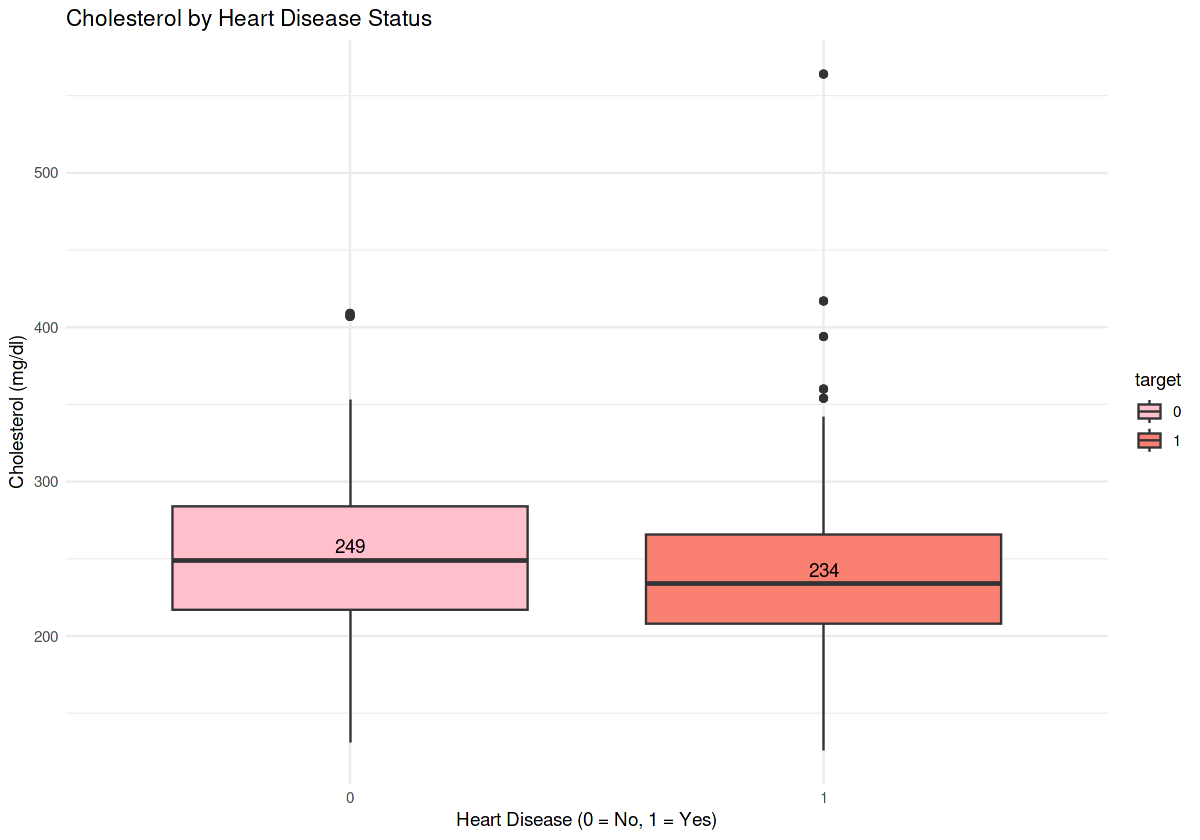

In [ ]:
# 2. Boxplot of cholesterol (chol) across levels of target
ggplot(heart_data1, aes(x = target, y = chol, fill = target)) +
  geom_boxplot() +
  stat_summary(fun = median, geom = "text", aes(label = round(after_stat(y),1)),
               position = position_nudge(x = 0), vjust = -0.5, color = "black") +
  labs(title = "Cholesterol by Heart Disease Status",
       x = "Heart Disease (0 = No, 1 = Yes)",
       y = "Cholesterol (mg/dl)") +
  scale_fill_manual(values = c("pink", "salmon")) +
  theme_minimal()

<h3>Cholesterol Boxplot Interpretation</h3>

<p style="font-size:18px; line-height:2;">
Patients with heart disease have a median cholesterol of <b>234 mg/dl</b>, while those without heart disease have a median of <b>249 mg/dl</b>. Individuals with heart disease show <b>many extreme cholesterol values (outliers)</b>, whereas those without heart disease have only <b>one outlier</b>. This suggests that extreme cholesterol levels are more common among patients with heart disease, even though the median is slightly lower.
</p>


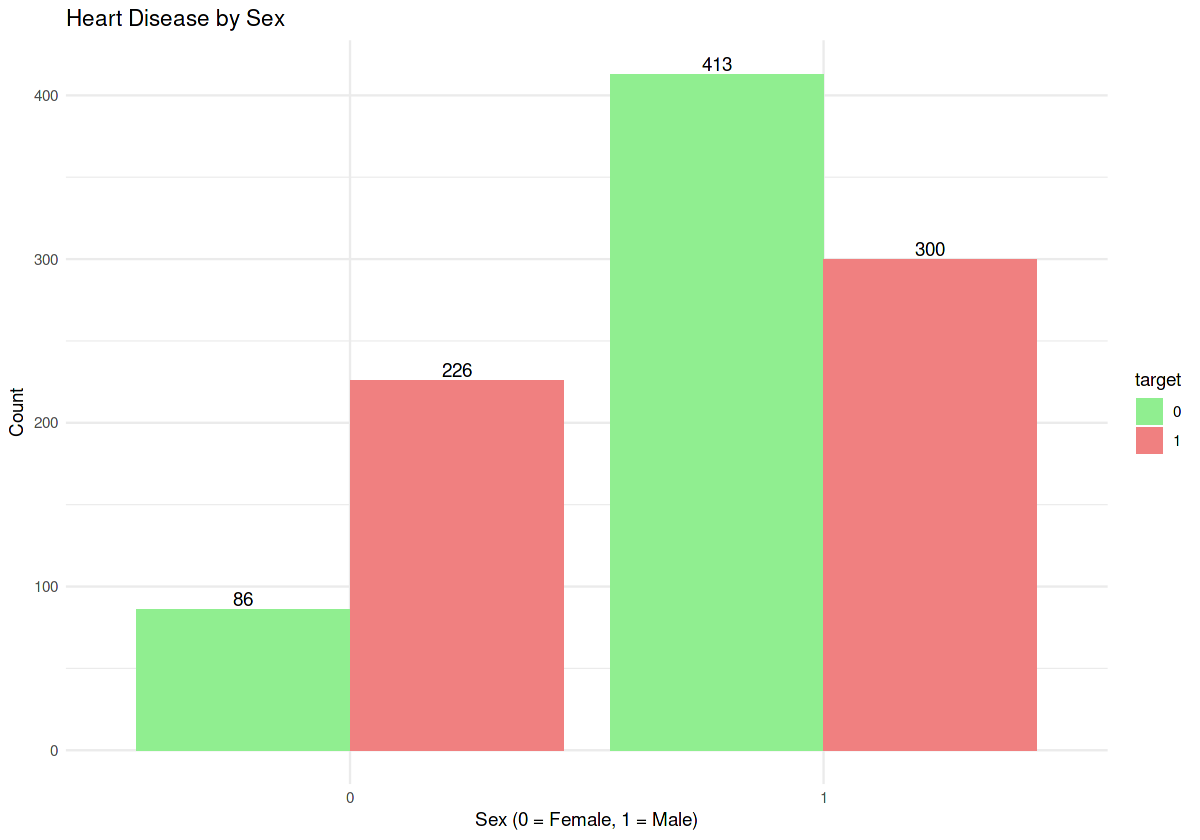

In [ ]:
# 3. Bar plot of sex vs target
ggplot(heart_data1, aes(x = sex, fill = target)) +
  geom_bar(position = "dodge") +
  geom_text(stat = "count", aes(label = after_stat(count)),
            position = position_dodge(width = 0.9), vjust = -0.25) +
  labs(title = "Heart Disease by Sex",
       x = "Sex (0 = Female, 1 = Male)",
       y = "Count") +
  scale_fill_manual(values = c("lightgreen", "lightcoral")) +
  theme_minimal()

<h3>Sex vs Target Bar Plot Interpretation</h3>

<p style="font-size:18px; line-height:2;">
In this dataset, heart disease is more common in males than in females. There are <b>413</b> males without heart disease and <b>226</b> females without heart disease. Among people with heart disease, there are <b>300</b> males and only <b>86</b> females. This shows that males are more likely to have heart disease than females. Therefore, sex may be an important factor when studying heart disease in this dataset.
</p>


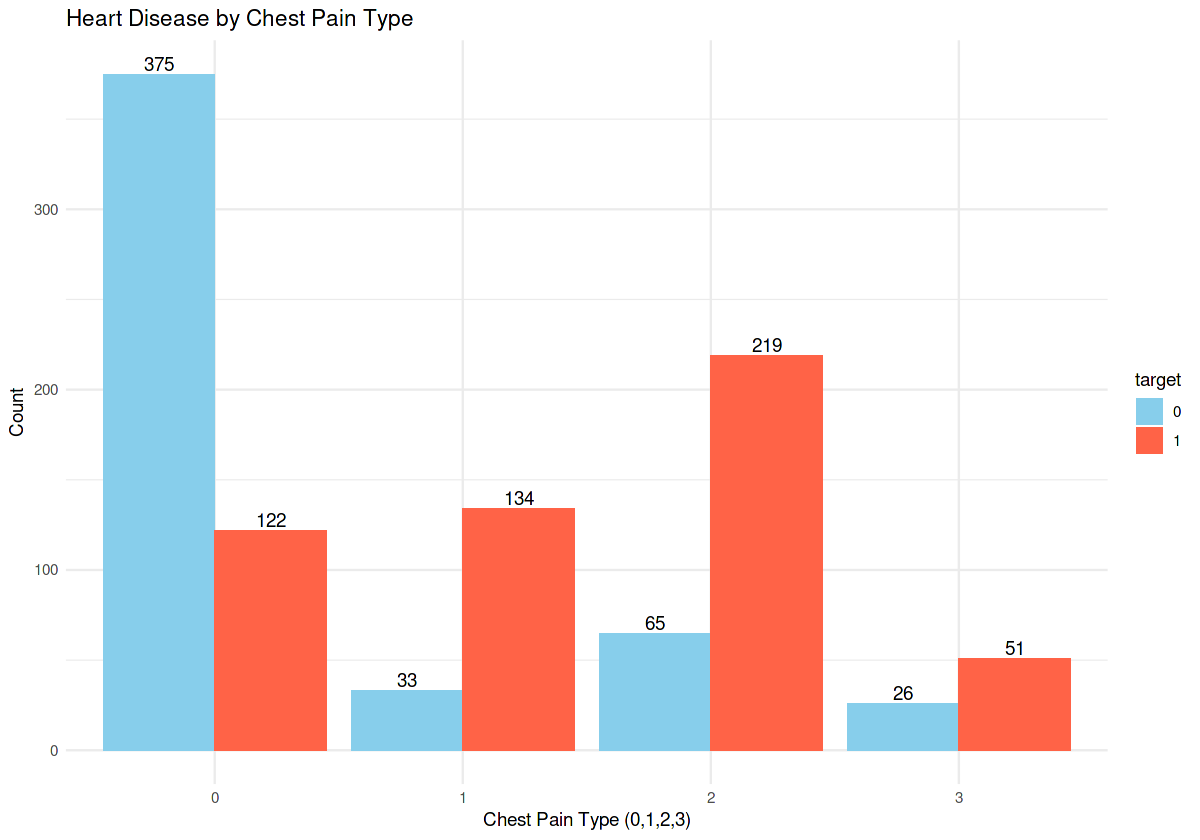

In [ ]:
# 4. Bar plot of chest pain type (cp) vs target
ggplot(heart_data1, aes(x = cp, fill = target)) +
  geom_bar(position = "dodge") +
  geom_text(stat = "count", aes(label = after_stat(count)),
            position = position_dodge(width = 0.9), vjust = -0.25) +
  labs(title = "Heart Disease by Chest Pain Type",
       x = "Chest Pain Type (0,1,2,3)",
       y = "Count") +
  scale_fill_manual(values = c("skyblue", "tomato")) +
  theme_minimal()


<h3>Chest Pain Type (cp) vs Target Bar Plot Interpretation</h3>

<p style="font-size:18px; line-height:2;">
In this dataset, the type of chest pain is linked to heart disease. Among people without heart disease, there are <b>375</b> with type 1 chest pain, <b>33</b> with type 2, <b>65</b> with type 3, and <b>26</b> with type 4. Among people with heart disease, there are <b>122</b> with type 1, <b>134</b> with type 2, <b>219</b> with type 3, and <b>51</b> with type 4. This shows that type 1 chest pain mostly occurs in patients without heart disease, while types 2, 3, and 4 are more common in patients with heart disease. Type 3 has the highest count among patients with heart disease, which suggests that higher chest pain types are strongly associated with having heart disease.
</p>


# 4. Fitting a Logistic Regression Model

In [ ]:
# Fit logistic regression model
logit_model <- glm(target ~ age + sex + cp + chol,
                   data = heart_data1,
                   family = binomial)

# View model summary
summary(logit_model)


Call:
glm(formula = target ~ age + sex + cp + chol, family = binomial, 
    data = heart_data1)

Deviance Residuals: 
    Min       1Q   Median       3Q      Max  
-2.3531  -0.6674   0.2024   0.7582   2.3816  

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept)  4.996073   0.689337   7.248 4.24e-13 ***
age         -0.063011   0.009710  -6.489 8.62e-11 ***
sex1        -1.951686   0.198638  -9.825  < 2e-16 ***
cp1          2.597544   0.241564  10.753  < 2e-16 ***
cp2          2.408265   0.194328  12.393  < 2e-16 ***
cp3          2.248427   0.289362   7.770 7.83e-15 ***
chol        -0.005501   0.001573  -3.497  0.00047 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 1420.24  on 1024  degrees of freedom
Residual deviance:  977.54  on 1018  degrees of freedom
AIC: 991.54

Number of Fisher Scoring iterations: 5


# Interpretation of Logistic Regression Coefficients


<p style="font-size:18px; line-height:2;">
<b>Age (age): </b> Estimate: <b> -0.0630</b>. Age has a negative effect on heart disease. As age increases, the odds of having heart disease <b>slightly decrease</b>.
</p>

<p style="font-size:18px; line-height:2;">
<b>Sex (sex1): </b> Estimate: <b> -1.9517</b>. Sex has a negative effect. Being <b>male</b> reduces the odds of heart disease compared to being female, after controlling for the other variables.
</p>

<p style="font-size:18px; line-height:2;">
<b>Chest Pain Type (cp1, cp2, cp3)</b> – Chest pain type has a strong positive effect on heart disease.  
<br>
<b>cp1:</b> Estimate <b>2.5975</b> — greatly increases the odds of heart disease compared to type 4.  
<br>
<b>cp2:</b> Estimate <b>2.4083</b> — also strongly increases the odds compared to type 4.  
<br>
<b>cp3:</b> Estimate <b>2.2484</b> — increases the odds compared to type 4.  
<br>
Overall, chest pain type is the <b>strongest predictor</b> in the model.
</p>

<p style="font-size:18px; line-height:2;">
<b>Cholesterol (chol):</b> Estimate: <b>-0.0055</b>. Cholesterol has a very small negative effect. Higher cholesterol values are associated with a <b>slight decrease</b> in heart disease likelihood in this dataset.
</p>


# 5. Model Interpretation

In [ ]:
# Convert coefficients to odds ratios
odds_ratios <- exp(coef(logit_model))

# Display the odds ratios
odds_ratios


(Intercept)         age        sex1         cp1         cp2         cp3 
147.8314503   0.9389328   0.1420344  13.4307149  11.1146634   9.4728261 
       chol 
  0.9945144

<p style="font-size:22px; font-weight:bold; line-height:2;">
Interpretation of Odds Ratios (sex, cp, chol)
</p>

<p style="font-size:18px; line-height:2;">
<b>Sex (sex1)</b> – Odds ratio: <b>0.142</b>.  
Being <b>male</b> is associated with much lower odds of heart disease compared to being female. Males have about <b>0.142 times the odds</b> of having heart disease (≈ <b>86% lower odds</b>) than females, after adjusting for the other variables.
</p>

<p style="font-size:18px; line-height:2;">
<b>Chest Pain Type (cp)</b> – Odds ratios relative to cp = 4:  
<br><b>cp1:</b> <b>13.43</b> — patients with cp1 have about <b>13.4 times higher odds</b> of heart disease than those with cp4 (≈ <b>1243% higher odds</b>).  
<br><b>cp2:</b> <b>11.11</b> — patients with cp2 have about <b>11.1 times higher odds</b> than cp4 (≈ <b>1011% higher odds</b>).  
<br><b>cp3:</b> <b>9.47</b> — patients with cp3 have about <b>9.47 times higher odds</b> than cp4 (≈ <b>847% higher odds</b>).  
Overall, higher chest pain types (1–3) are strongly associated with much greater odds of heart disease compared to type 4.
</p>

<p style="font-size:18px; line-height:2;">
<b>Cholesterol (chol)</b> – Odds ratio: <b>0.9945</b>.  
Each 1 mg/dl increase in cholesterol is associated with the odds of heart disease being multiplied by about <b>0.9945</b>, i.e. a <b>very small decrease</b> in odds (≈ <b>0.55% lower odds per 1 mg/dl</b>). This effect is tiny and opposite to usual clinical expectations, but that is what the model shows for this dataset.
</p>


# 6. Model Comparison

In [ ]:
# 1. Fit the reduced model without cholesterol
reduced_model <- glm(target ~ age + sex + cp, data = heart_data1, family = binomial)

summary(reduced_model)

# 2. Perform likelihood ratio test to compare full vs reduced models
anova_result <- anova(reduced_model, logit_model, test = "Chisq")

anova_result



Call:
glm(formula = target ~ age + sex + cp, family = binomial, data = heart_data1)

Deviance Residuals: 
    Min       1Q   Median       3Q      Max  
-2.2649  -0.7259   0.2373   0.7433   2.2595  

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept)  3.739627   0.573892   6.516 7.21e-11 ***
age         -0.066961   0.009559  -7.005 2.47e-12 ***
sex1        -1.791697   0.189715  -9.444  < 2e-16 ***
cp1          2.561954   0.239299  10.706  < 2e-16 ***
cp2          2.411452   0.192865  12.503  < 2e-16 ***
cp3          2.274265   0.287080   7.922 2.34e-15 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 1420.24  on 1024  degrees of freedom
Residual deviance:  989.79  on 1019  degrees of freedom
AIC: 1001.8

Number of Fisher Scoring iterations: 5


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1019,989.7900,NA,NA,NA
2,1018,977.5401,1,12.2499,0.0004652843


<p style="font-size:22px; font-weight:bold; line-height:2;">
Effect of Including Cholesterol on Model Fit
</p>

<p style="font-size:18px; line-height:2;">
A likelihood ratio test was performed to compare the reduced model (without <b>chol</b>) and the full model (with <b>chol</b>). The results are as follows:<br>
Residual deviance of reduced model: 989.79 (df = 1019)<br>
Residual deviance of full model: 977.54 (df = 1018)<br>
Chi-square = 12.25, p-value = 0.000465
</p>

<p style="font-size:18px; line-height:2;">
Since the p-value is much smaller than 0.05, the difference between the two models is statistically significant. This means that including <b>cholesterol</b> significantly improves the model’s fit and helps predict heart disease more accurately, even though the effect of cholesterol is relatively small.
</p>


# 7. Model Predictions and Performance

In [ ]:
# 1. Predict probabilities of heart disease
predicted_prob <- predict(logit_model, type = "response")

# 2. Convert probabilities to binary predictions using threshold = 0.5
predicted_class <- ifelse(predicted_prob >= 0.5, 1, 0)

# Convert both to factors for confusion matrix
predicted_class <- factor(predicted_class, levels = c(0, 1))
actual_class <- factor(heart_data1$target, levels = c(0, 1))

# 3. Create confusion matrix
confusion_matrix <- table(Predicted = predicted_class, Actual = actual_class)

confusion_matrix


         Actual
Predicted   0   1
        0 379 102
        1 120 424

<p style="font-size:22px; font-weight:bold; line-height:2;">
Model Accuracy and Errors
</p>

<p style="font-size:18px; line-height:2;">
<b>Confusion Matrix:</b><br>
Predicted vs Actual<br>
0: No heart disease, 1: Heart disease<br>
<table>
<tr><th>Predicted</th><th>Actual 0</th><th>Actual 1</th></tr>
<tr><td>0</td><td>379</td><td>102</td></tr>
<tr><td>1</td><td>120</td><td>424</td></tr>
</table>
</p>

<p style="font-size:18px; line-height:2;">
<b>Accuracy:</b> The model correctly predicts heart disease status about <b>78.3%</b> of the time.
</p>

<p style="font-size:18px; line-height:2;">
<b>False Positives (Type I error):</b> 120 cases. These are individuals predicted to have heart disease but actually do not.  
<b>False Negatives (Type II error):</b> 102 cases. These are individuals predicted not to have heart disease but actually do.
</p>

<p style="font-size:18px; line-height:2;">
Overall, the model performs reasonably well but does make some errors in predicting both the presence and absence of heart disease.
</p>


# 8. ROC Curve and AUC

Setting levels: control = 0, case = 1

Setting direction: controls < cases



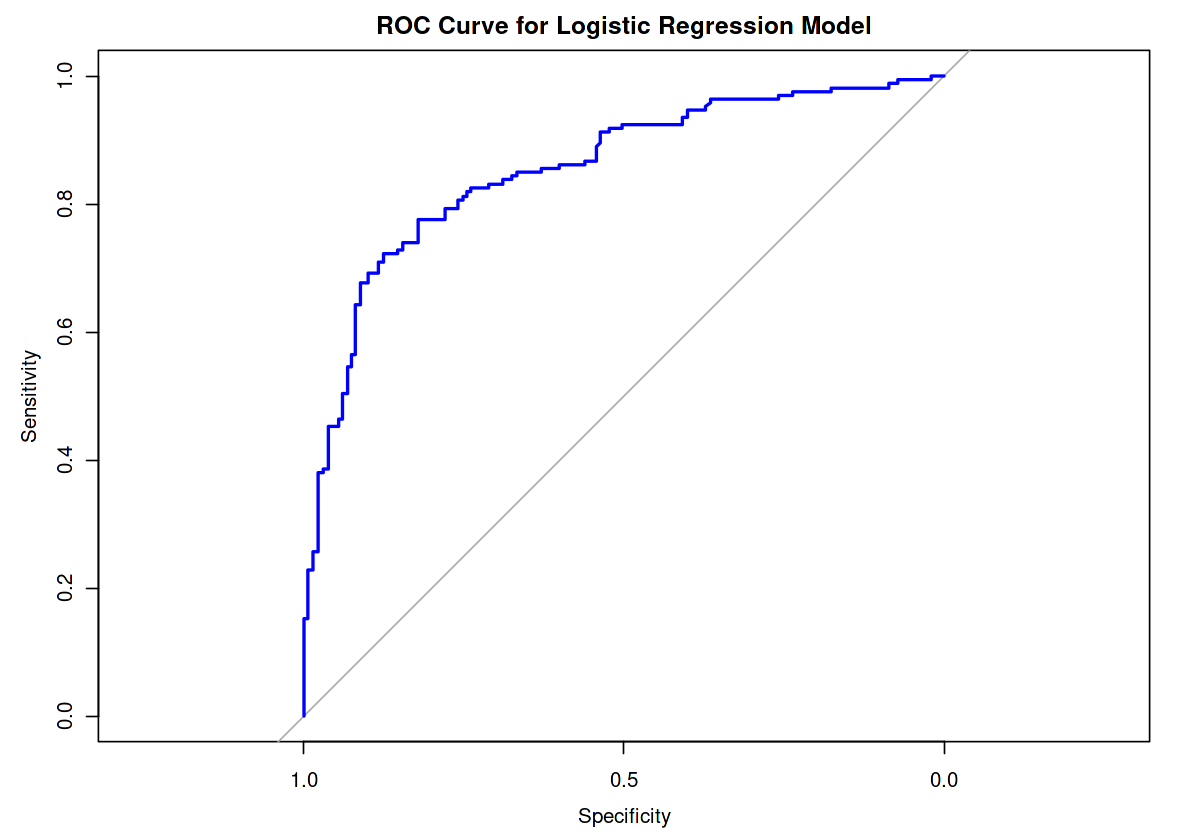

In [ ]:
# Generate ROC curve
roc_curve <- roc(heart_data1$target, predicted_prob)

# Plot ROC curve
plot(roc_curve, col = "blue", lwd = 2, main = "ROC Curve for Logistic Regression Model")



In [ ]:
# Calculate AUC
auc_value <- auc(roc_curve)
auc_value

Area under the curve: 0.8545

<p style="font-size:20px; line-height:2;">
<strong>ROC Curve and AUC Interpretation</strong>
</p>

<p style="font-size:18px; line-height:2;">
The Area Under the Curve (AUC) for the logistic regression model is <strong>0.8545</strong>. AUC values range from 0.5 to 1: <br>
0.5 indicates that the model performs no better than random guessing, <br>
0.7–0.8 indicates acceptable discrimination, <br>
0.8–0.9 indicates excellent discrimination, and <br>
1 indicates perfect discrimination.
</p>

<p style="font-size:18px; line-height:2;">
Since the AUC is 0.8545, the model is <strong>excellent at distinguishing</strong> between individuals with and without heart disease. In practical terms, this means that for a randomly chosen pair of patients, one with heart disease and one without, the model has an approximately 85.5% chance of correctly assigning a higher predicted probability to the patient with heart disease.
</p>
